In [1]:
import cv2 as cv
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import numpy.typing as npt
import matplotlib.pyplot as plt
from timeit import repeat

In [2]:
## Assert the shape of grey
grey = cv.imread("portrait.png", cv.IMREAD_GRAYSCALE)
grey_height, grey_width = grey.shape

assert (grey_height, grey_width) == (320, 480)

In [3]:
def correlate(img, kernel, mode=cv.BORDER_REFLECT_101):
    border_modes = {
            cv.BORDER_CONSTANT: "constant",
            cv.BORDER_REPLICATE: "edge",
            cv.BORDER_REFLECT: "symmetric",
            cv.BORDER_REFLECT_101: "reflect",
    }
    border_mode = border_modes.get(mode)
    pad = kernel.shape[0] // 2
    padded = np.pad(img.astype(np.float32), pad, mode=border_mode)
    windows = sliding_window_view(padded, kernel.shape)  # (h, w, kh, kw)
    return np.einsum("ijkl,kl->ij", windows, kernel.astype(np.float32))


box_kernel = np.ones((5, 5), dtype=np.float32) / 25.0
async_kernel = np.array([[0, 0, 0], [0, 0, 1], [0, 0, 0]], dtype=np.float32) / 9.0
async_kernel_flipped = async_kernel.copy()[::-1, ::-1]

correlate_box = correlate(grey, box_kernel)
cv_filter_box = cv.filter2D(grey, cv.CV_32F, box_kernel)
assert np.allclose(correlate_box, cv_filter_box, atol=1e-3, rtol=0)

correlate_async = correlate(grey, async_kernel)
cv_filter_async = cv.filter2D(grey, cv.CV_32F, async_kernel)
assert np.allclose(correlate_async, cv_filter_async, atol=1e-3, rtol=0)

correlate_async_flipped = correlate(grey, async_kernel_flipped)
assert not np.allclose(correlate_async_flipped, cv_filter_async, atol=1e-3, rtol=0)

max_kernel_diff = np.abs(cv_filter_async - correlate_async_flipped).max()
print(f"Maximum difference: {max_kernel_diff}")

Maximum difference: 24.333332061767578


A flipped box kernel (180 degree flip) won't change the box kernel because it will still have the same values in the same positions as the previous, since they all have the same values

Text(0.5, 1.0, 'Reflect 101 border')

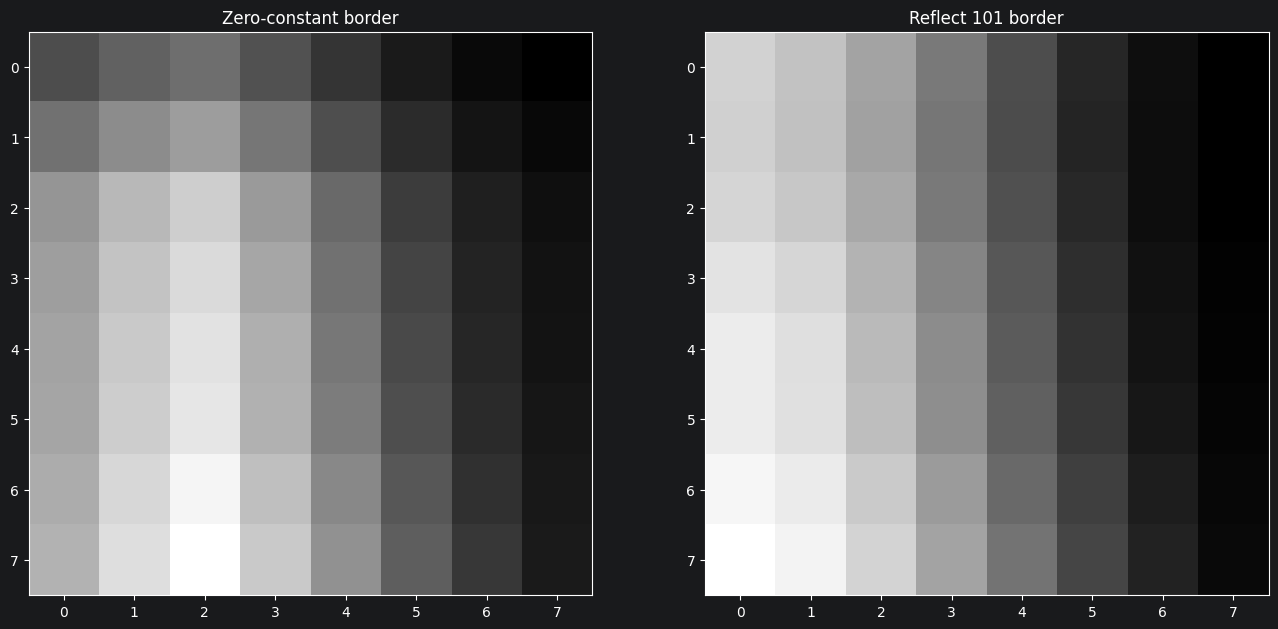

In [4]:
zero_result = correlate(grey, box_kernel, mode=cv.BORDER_CONSTANT)
reflect_result = correlate(grey, box_kernel, mode=cv.BORDER_REFLECT_101)

zero_top_left = zero_result[:8, :8]
reflect_top_left = reflect_result[:8, :8]

# Plot them side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(zero_top_left, cmap="gray")
axes[0].set_title("Zero-constant border")
axes[1].imshow(reflect_top_left, cmap="gray")
axes[1].set_title("Reflect 101 border")

In [5]:
kernel = np.ones((3, 3), dtype=np.float32)

result_uint8 = cv.filter2D(grey, ddepth=-1, kernel=kernel)
result_float = cv.filter2D(grey, ddepth=cv.CV_32F, kernel=kernel)

uint_count = np.count_nonzero(result_uint8 > 255)
float_count = np.count_nonzero(result_float > 255)
print(f"uint8 above 255: {uint_count}. float above 255: {float_count}")

result_float_clipped = np.clip(np.round(result_float), 0, 255)
assert np.array_equal(result_float_clipped, result_uint8)

uint8 above 255: 0. float above 255: 131043


In [6]:
kernel = np.array([[0, 0, 0], [-1, 0, 1], [0, 0, 0]])

result_uint8 = cv.filter2D(grey, ddepth=-1, kernel=kernel)
result_float = cv.filter2D(grey, ddepth=cv.CV_32F, kernel=kernel)

uint_count = np.count_nonzero(result_uint8 > 255)
float_count = np.count_nonzero(result_float > 255)
print(f"uint8 above 255: {uint_count}. float above 255: {float_count}")

result_float_clipped = np.clip(np.round(result_float), 0, 255)
assert np.array_equal(result_float_clipped, result_uint8)

uint8 above 255: 0. float above 255: 0


The `uint8` output clips negative edge responses to zero, losing information about intensity transitions from bright to dark (left to right).

In [7]:
def correlate_separable(img, v):
    v = np.asarray(v, dtype=np.float32)
    img = img.astype(np.float32)

    pad = len(v) // 2

    # Vertical correlation
    padded_v = np.pad(img, ((pad, pad), (0, 0)), mode="reflect")
    windows_v = sliding_window_view(padded_v, (len(v), 1))
    result_v = np.einsum("ijkl,k->ij", windows_v, v)

    # Horizontal correlation
    padded_h = np.pad(result_v, ((0, 0), (pad, pad)), mode="reflect")
    windows_h = sliding_window_view(padded_h, (1, len(v)))
    result_h = np.einsum("ijkl,l->ij", windows_h, v)

    return result_h


kernel_v = np.ones(5, dtype=np.float32) / 5.0

separable_result = correlate_separable(grey, kernel_v)

box_kernel = np.outer(kernel_v, kernel_v)
box_result = correlate(grey, box_kernel)
cv_result = cv.sepFilter2D(
        grey,
        cv.CV_32F,
        kernelX=kernel_v,
        kernelY=kernel_v,
        borderType=cv.BORDER_REFLECT_101
)

assert np.allclose(separable_result, box_result, atol=1e-3, rtol=0)
assert np.allclose(separable_result, cv_result, atol=1e-3, rtol=0)
assert np.allclose(box_result, cv_result, atol=1e-3, rtol=0)

In [8]:
def benchmark(size: int, img=grey):
    repeat_number = 10
    repeat_repeats = 5

    v = np.ones(size, dtype=np.float32) / size
    box_kernel = np.outer(v, v)

    # Compute results
    result_2d = correlate(img, box_kernel)
    result_sep = correlate_separable(img, v)

    result_cv = cv.sepFilter2D(
            img,
            cv.CV_32F,
            kernelX=v,
            kernelY=v,
            borderType=cv.BORDER_REFLECT_101
    )

    assert np.allclose(result_sep, result_2d, atol=1e-3, rtol=0)
    assert np.allclose(result_sep, result_cv, atol=1e-3, rtol=0)
    assert np.allclose(result_2d, result_cv, atol=1e-3, rtol=0)

    times_2d = repeat(
            lambda: correlate(img, box_kernel),
            number=repeat_number,
            repeat=repeat_repeats
    )

    times_sep = repeat(
            lambda: correlate_separable(img, v),
            number=repeat_number,
            repeat=repeat_repeats
    )

    # Median execution time per call
    time_2d = np.median(times_2d) / repeat_number
    time_sep = np.median(times_sep) / repeat_number

    speedup = time_2d / time_sep

    print(f"\n{size}x{size} kernel")
    print(f"2-D correlation:      {time_2d * 1000:.3f} ms")
    print(f"Separable correlation: {time_sep * 1000:.3f} ms")
    print(f"Speed-up:             {speedup:.2f}x")

    return speedup


speedup_5 = benchmark(5, grey)
speedup_15 = benchmark(15, grey)

assert speedup_15 > 1


5x5 kernel
2-D correlation:      3.224 ms
Separable correlation: 0.679 ms
Speed-up:             4.75x

15x15 kernel
2-D correlation:      12.151 ms
Separable correlation: 0.897 ms
Speed-up:             13.55x


In [9]:
identity_kernel = np.zeros((3, 3), dtype=np.float32)
identity_kernel[1, 1] = 1

shift_left_kernel = np.zeros((3, 3), dtype=np.float32)
shift_left_kernel[1, 2] = 1

box_kernel = np.ones((3, 3), dtype=np.float32) / 9

difference_kernel = np.zeros((3, 3), dtype=np.float32)
difference_kernel[1, 0] = -1
difference_kernel[1, 2] = 1

kernels = {
        "Identity": identity_kernel,
        "Shift Left": shift_left_kernel,
        "Box": box_kernel,
        "Difference": difference_kernel,
}

results = {}

for name, kernel in kernels.items():
    results[name] = cv.filter2D(grey, cv.CV_32F, kernel)

assert np.array_equal(results["Identity"], grey)
